<a href="https://colab.research.google.com/github/athfizh/PemMes26_05_Hafizh/blob/main/JS07/JS07-TugasLab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---


# **Klasterisasi - Tugas Lab**


---

---


# **Langkah 0 - Import Library**


---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors

---


# **Langkah 1 - Load dan Inspeksi Data**


---

In [2]:
df = pd.read_csv('CC_Customer_Dataset.csv')
df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


> `df.head()` nampilin 5 baris pertama. Satu baris mewakili satu nasabah: ada kolom identitas (`Sl_No`, `Customer Key`), `Avg_Credit_Limit`, `Total_Credit_Cards`, lalu `Total_visits_bank`, `Total_visits_online`, dan `Total_calls_made`. Kolom identitas tidak dipakai karena klasterisasi tidak butuh label.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


> 660 baris, 7 kolom, semuanya `int64` dan tidak ada nilai kosong. Jadi data bisa langsung dipakai tanpa imputasi.

In [4]:
df.describe()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
count,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000
mean,330.500000,55141.443939,34574.242424,4.706061,2.403030,2.606061,3.583333
std,190.669872,25627.772200,37625.487804,2.167835,1.631813,2.935724,2.865317
min,1.000000,11265.000000,3000.000000,1.000000,0.000000,0.000000,0.000000
25%,165.750000,33825.250000,10000.000000,3.000000,1.000000,1.000000,1.000000
50%,330.500000,53874.500000,18000.000000,5.000000,2.000000,2.000000,3.000000
75%,495.250000,77202.500000,48000.000000,6.000000,4.000000,4.000000,5.000000
max,660.000000,99843.000000,200000.000000,10.000000,5.000000,15.000000,10.000000


> `Avg_Credit_Limit` berkisar 3.000-200.000 dengan rata-rata 34.574, sementara kolom lain cuma 0-15. Selisih skala ini yang bikin `Avg_Credit_Limit` mendominasi kalau jarak antar titik dihitung, jadi perlu standardisasi sebelum DBSCAN.

---


# **Langkah 2 - Seleksi Variabel**


---

In [5]:
# Dua variabel untuk Tugas 1 - 3
X = df[['Avg_Credit_Limit', 'Total_Credit_Cards']]

# Seluruh variabel yang dapat digunakan untuk Tugas 4 - 6
X_all = df.drop(columns=['Sl_No', 'Customer Key'])

print('X     :', X.shape)
print('X_all :', X_all.shape)
print('Kolom X_all:', list(X_all.columns))

X     : (660, 2)
X_all : (660, 5)
Kolom X_all: ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


> `X` isi dua variabel buat Tugas 1-3, `X_all` isi lima variabel buat Tugas 4-6. `Sl_No` dan `Customer Key` dibuang karena cuma identitas.

---


# **Tugas 1 - Scatterplot Avg_Credit_Limit dan Total_Credit_Cards**


---

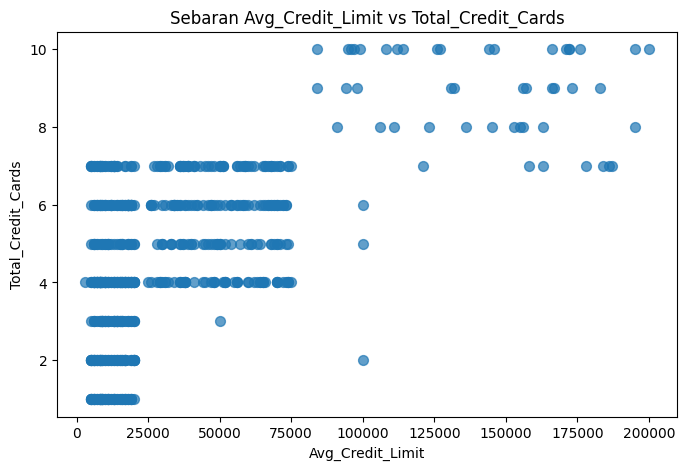

In [6]:
plt.figure(figsize=(8, 5))
plt.scatter(X['Avg_Credit_Limit'], X['Total_Credit_Cards'], s=50, alpha=0.7)
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Sebaran Avg_Credit_Limit vs Total_Credit_Cards')
plt.show()

> Sebaran datanya tidak linier. Titik menumpuk di nilai `Total_Credit_Cards` 1-7 sehingga terbentuk garis-garis horizontal, terutama di limit bawah 75.000. Di atas 100.000 semua titik punya 7-10 kartu (rata-rata 8,7), sedangkan di bawah 75.000 cuma 1-7 kartu (rata-rata 4,4). Karena hubungannya tidak lurus, analisisnya lebih pas pakai klasterisasi.

---


# **Tugas 2 - Menentukan k Terbaik dengan Elbow Method**


---

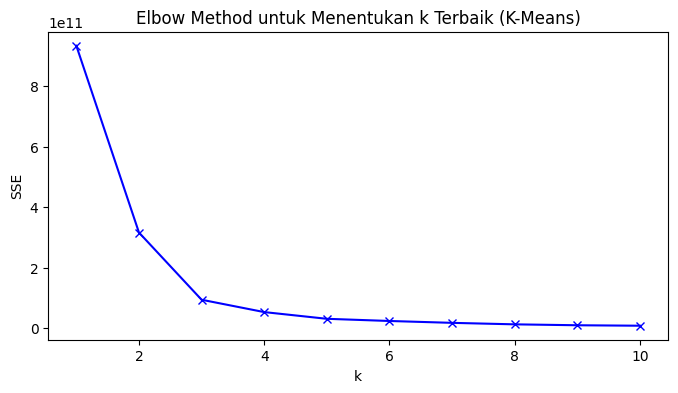

In [7]:
# Mencari k terbaik dengan Elbow Method
sse = []
K = range(1, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=0, n_init=10)
    kmeans.fit(X)
    sse.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K, sse, 'bx-')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Elbow Method untuk Menentukan k Terbaik (K-Means)')
plt.show()

> SSE turun dari 9,3 x 10^11 (k=1) ke 3,2 x 10^11 (k=2), lalu 9,4 x 10^10 (k=3). Setelah k=3 penurunannya landai, jadi sikunya di k=3 dan k=3 yang dipakai. Hasilnya masuk akal: segmen limit rendah, menengah, dan tinggi. Angka SSE besar karena `Avg_Credit_Limit` tidak dinormalisasi, tapi posisi sikunya tetap kebaca.

---


# **Tugas 3 - Klasterisasi dengan K-Means**


---

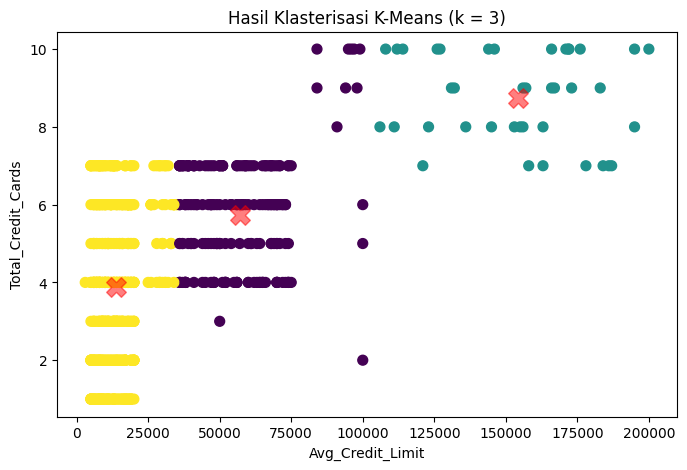

In [8]:
# Model K-Means dengan k terbaik hasil elbow method
kmeans = KMeans(n_clusters=3, random_state=0, n_init=10)
cluster_kmeans = kmeans.fit_predict(X)

plt.figure(figsize=(8, 5))
plt.scatter(X['Avg_Credit_Limit'], X['Total_Credit_Cards'], c=cluster_kmeans, s=50, cmap='viridis')

# Plot centroid
centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5, marker='X')

plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Hasil Klasterisasi K-Means (k = 3)')
plt.show()

> Dengan k=3 terbentuk tiga kelompok. Kuning (label 2): 431 nasabah, limit rata-rata 13.849, 1-7 kartu. Ungu (label 0): 190 nasabah, limit rata-rata 57.032, 2-10 kartu. Hijau (label 1): 39 nasabah, limit rata-rata 154.205, 7-10 kartu. Tanda X merah adalah centroid tiap klaster.

In [9]:
print(f'Silhouette Score K-Means: {silhouette_score(X, cluster_kmeans)}')
print(f'Davies-Bouldin Index K-Means: {davies_bouldin_score(X, cluster_kmeans)}')

Silhouette Score K-Means: 0.7187201698623006
Davies-Bouldin Index K-Means: 0.3998657016734477


> Silhouette 0.719 dan DBI 0.400. Silhouette mendekati 1 berarti anggota klaster rapat dan antar klaster berjauhan; DBI kecil berarti jarak antar klaster besar dibanding sebaran di dalamnya. Jadi pembagian k=3 di dua variabel ini cukup rapi.

---


# **Tugas 4 - Klasterisasi dengan DBSCAN (Seluruh Variabel)**


---

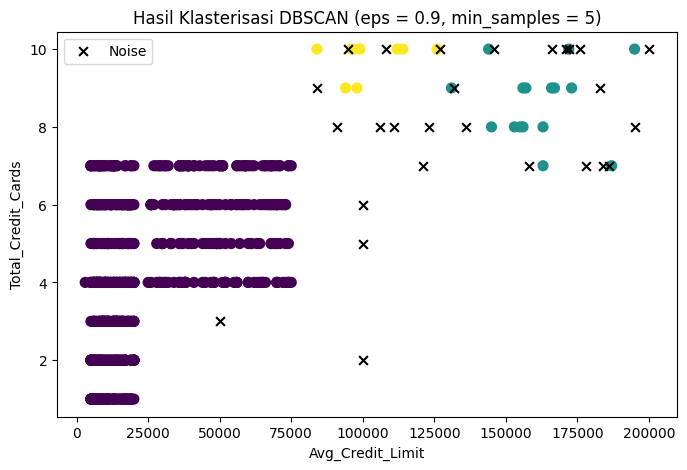

Label klaster: [-1  0  1  2]
Jumlah anggota tiap label:
-1     27
 0    608
 1     16
 2      9
Name: count, dtype: int64


In [10]:
# Standardisasi agar seluruh variabel berada pada skala yang sebanding
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_all)

# Klasterisasi DBSCAN dengan seluruh variabel
dbscan = DBSCAN(eps=0.9, min_samples=5)
cluster_db = dbscan.fit_predict(X_scaled)

# Pisahkan noise (label -1) supaya tidak tertukar dengan klaster 0
noise = cluster_db == -1

plt.figure(figsize=(8, 5))
plt.scatter(X['Avg_Credit_Limit'][~noise], X['Total_Credit_Cards'][~noise],
            c=cluster_db[~noise], s=50, cmap='viridis')
plt.scatter(X['Avg_Credit_Limit'][noise], X['Total_Credit_Cards'][noise],
            c='black', s=40, marker='x', label='Noise')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Hasil Klasterisasi DBSCAN (eps = 0.9, min_samples = 5)')
plt.legend()
plt.show()

print('Label klaster:', np.unique(cluster_db))
print('Jumlah anggota tiap label:')
print(pd.Series(cluster_db).value_counts().sort_index())

> DBSCAN dijalankan di lima variabel, jadi datanya distandardisasi dulu supaya skalanya sebanding. Dengan `eps=0.9` dan `min_samples=5` (pemilihan eps dijelaskan di Tugas 5) didapat 3 klaster dan 27 titik noise (label -1). Plot tetap pakai dua variabel biar bisa dibandingkan sama hasil K-Means, dan titik noise ditandai x hitam.

---


# **Tugas 5 - Menentukan eps Terbaik dengan Elbow Method (k-distance)**


---

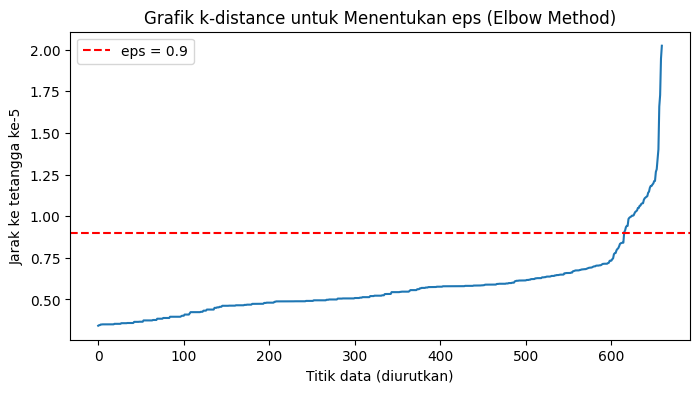

In [11]:
# Grafik k-distance: jarak tiap titik ke tetangga ke-k, diurutkan naik
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

distances = np.sort(distances[:, -1], axis=0)

plt.figure(figsize=(8, 4))
plt.plot(distances)
plt.axhline(y=0.9, color='red', linestyle='--', label='eps = 0.9')
plt.xlabel('Titik data (diurutkan)')
plt.ylabel('Jarak ke tetangga ke-5')
plt.title('Grafik k-distance untuk Menentukan eps (Elbow Method)')
plt.legend()
plt.show()

> DBSCAN tidak pakai jumlah klaster, jadi parameternya `eps` (padanan 'k' pada tugas ini). Caranya sama seperti elbow: jarak tiap titik ke tetangga ke-5 diurutkan lalu dicari titik sikunya. Kurvanya datar di 0.35-0.7, naik tajam setelah titik ke-600, dan sikunya sekitar 0.75-0.9. Saya ambil `eps = 0.9`.

In [12]:
hasil = []

for eps in [0.6, 0.7, 0.8, 0.9, 1.0]:
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_scaled)
    n_cluster = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
    sil = silhouette_score(X_scaled, labels) if n_cluster > 1 else np.nan
    dbi = davies_bouldin_score(X_scaled, labels) if n_cluster > 1 else np.nan
    hasil.append([eps, n_cluster, n_noise, round(n_noise / len(labels) * 100, 2), sil, dbi])

pd.DataFrame(hasil, columns=['eps', 'Jumlah Klaster', 'Jumlah Noise', 'Noise (%)', 'Silhouette', 'DBI']).round(4)

,eps,Jumlah Klaster,Jumlah Noise,Noise (%),Silhouette,DBI
0,0.6,8,82,12.42,-0.0087,2.1639
1,0.7,1,58,8.79,NaN,NaN
2,0.8,2,44,6.67,0.4895,2.0349
3,0.9,3,27,4.09,0.4645,1.9420
4,1.0,2,18,2.73,0.5212,2.1613


> Pembanding eps 0.6 sampai 1.0. Di 0.6 klaster pecah jadi 8 dengan noise 12,42% dan silhouette negatif. Di 0.7 semua menyatu jadi 1 klaster. Di 0.9 dapat 3 klaster dengan noise 4,09%. Di 1.0 tinggal 2 klaster karena ada yang bergabung. Jadi 0.9 yang paling seimbang.

---


# **Tugas 6 - Evaluasi DBSCAN (Silhouette Score dan DBI)**


---

In [13]:
print(f'Silhouette Score DBSCAN: {silhouette_score(X_scaled, cluster_db)}')
print(f'Davies-Bouldin Index DBSCAN: {davies_bouldin_score(X_scaled, cluster_db)}')

Silhouette Score DBSCAN: 0.4645014431416295
Davies-Bouldin Index DBSCAN: 1.942033774109667


> Silhouette 0.465 dan DBI 1.942, dihitung dengan noise ikut sebagai satu kelompok. Kalau noise dibuang, silhouette naik ke 0.494 dan DBI turun ke 0.878. Angkanya lebih rendah dari K-Means, tapi tidak bisa dibandingkan langsung: K-Means pakai dua variabel tanpa scaling, DBSCAN pakai lima variabel terstandardisasi.

> Ringkasnya, sebaran `Avg_Credit_Limit` vs `Total_Credit_Cards` tidak linier, k terbaik untuk K-Means adalah 3, dan DBSCAN di lima variabel dengan `eps=0.9`, `min_samples=5` menghasilkan 3 klaster plus 27 noise. Nilai eps diambil dari siku grafik k-distance. Metrik DBSCAN (0.465 dan 1.942) lebih rendah dari K-Means (0.719 dan 0.400), tapi keduanya dihitung pada data yang berbeda.